# 02 · Feature engineering, model training and experiment tracking
Runs the same `heartml.train` module used by CI. Every grid point is an MLflow run.

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
os.environ["HEARTML_ROOT"] = str(ROOT)
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.width", 140)

## 1. Preprocessing pipeline
One `ColumnTransformer`, persisted together with the model.

In [2]:
from heartml import config
from heartml.features import build_preprocessor
from heartml.data import load_clean, split_xy
df = load_clean(config.CLEAN_DATA_PATH); X, y = split_xy(df)
pre = build_preprocessor().fit(X)
print("numeric :", config.NUMERIC_FEATURES)
print("one-hot :", config.CATEGORICAL_FEATURES)
print("output features:", len(pre.get_feature_names_out()))
list(pre.get_feature_names_out())

numeric : ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
one-hot : ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
output features: 25


['age',
 'trestbps',
 'chol',
 'thalach',
 'oldpeak',
 'ca',
 'sex_0.0',
 'sex_1.0',
 'cp_1.0',
 'cp_2.0',
 'cp_3.0',
 'cp_4.0',
 'fbs_0.0',
 'fbs_1.0',
 'restecg_0.0',
 'restecg_1.0',
 'restecg_2.0',
 'exang_0.0',
 'exang_1.0',
 'slope_1.0',
 'slope_2.0',
 'slope_3.0',
 'thal_3.0',
 'thal_6.0',
 'thal_7.0']

## 2. Candidate models and search spaces

In [3]:
from heartml.train import model_specs
for name, (est, grid) in model_specs().items():
    n = int(np.prod([len(v) for v in grid.values()]))
    print(f"{name:20s} {n:3d} candidates  {grid}")

logistic_regression   28 candidates  {'model__C': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0], 'model__l1_ratio': [0.0, 1.0], 'model__class_weight': [None, 'balanced']}
random_forest         36 candidates  {'model__n_estimators': [200, 500], 'model__max_depth': [3, 5, None], 'model__min_samples_leaf': [1, 3, 5], 'model__max_features': ['sqrt', 0.5]}


Why these two:
- **Logistic Regression** – interpretable coefficients (odds ratios), strong on small tabular data; L1 vs L2 and C control complexity.
- **Random Forest** – captures non-linearities/interactions without scaling; depth and leaf size control over-fitting.

Protocol: stratified 80/20 split → 5-fold stratified CV grid search on the 80 % (scoring accuracy, precision, recall, F1, ROC-AUC; refit on ROC-AUC) → the 20 % hold-out is only used to report final numbers. A majority-class baseline is logged for reference.

## 3. Train + track

In [4]:
from heartml.train import train
summary = train(fast=False, register=True)
print("selected:", summary["selected_model"])

2026-10-19 02:39:58,609 INFO Train 242 rows / test 61 rows


2026/10/19 02:39:59 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/19 02:39:59 INFO mlflow.store.db.utils: Updating database tables


2026-10-19 02:40:14,673 INFO logistic_regression best {'C': 0.1, 'class_weight': 'None', 'l1_ratio': 0.0} | CV ROC-AUC 0.912 ± 0.017 | test ROC-AUC 0.962


2026-10-19 02:41:32,329 INFO random_forest best {'max_depth': 'None', 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 500} | CV ROC-AUC 0.898 ± 0.029 | test ROC-AUC 0.953


2026-10-19 02:41:32,336 INFO Selected model: logistic_regression


Successfully registered model 'heart-disease-classifier'.
2026/10/19 02:41:36 WARNING mlflow.tracking._model_registry.fluent: Run with id 8ba78a76c2474065a81e2a9e6c9fc052 has no artifacts at artifact path 'model', registering model based on models:/m-ecd537a878bd47398caaa5be4df89f59 instead


Created version '1' of model 'heart-disease-classifier'.
2026-10-19 02:41:36,197 INFO Registered heart-disease-classifier v1 (alias: champion)


selected: logistic_regression


In [5]:
rows = []
for name, r in summary["models"].items():
    rows.append({"model": name, **{f"cv_{k}": round(v, 3) for k, v in r["cv"].items() if k.endswith("mean")},
                 "test_roc_auc": round(r["test"]["test_roc_auc"], 3),
                 "test_accuracy": round(r["test"]["test_accuracy"], 3),
                 "train-cv gap": round(r["train_minus_cv_roc_auc"], 3), "best_params": r["best_params"]})
rows.append({"model": "baseline (majority)", "cv_accuracy_mean": round(summary["baseline"]["cv_accuracy_mean"], 3),
             "cv_roc_auc_mean": 0.5})
pd.DataFrame(rows)

,model,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean,test_roc_auc,test_accuracy,train-cv gap,best_params
0,logistic_regression,0.847,0.869,0.792,0.826,0.912,0.962,0.885,0.014,"{'C': 0.1, 'class_weight': 'None', 'l1_ratio':..."
1,random_forest,0.810,0.808,0.774,0.787,0.898,0.953,0.885,0.089,"{'max_depth': 'None', 'max_features': 'sqrt', ..."
2,baseline (majority),0.541,NaN,NaN,NaN,0.500,NaN,NaN,NaN,NaN


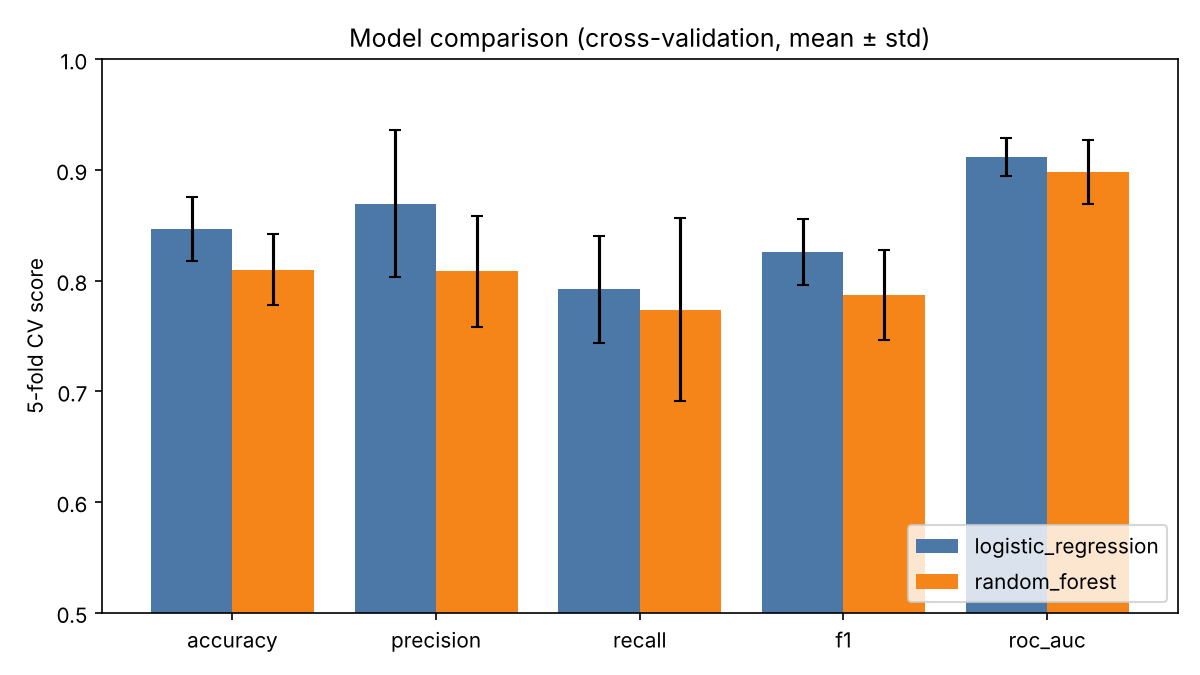

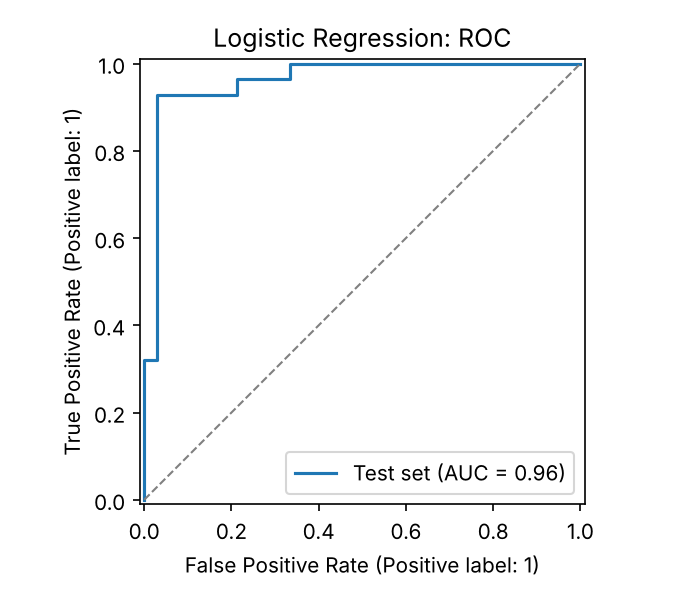

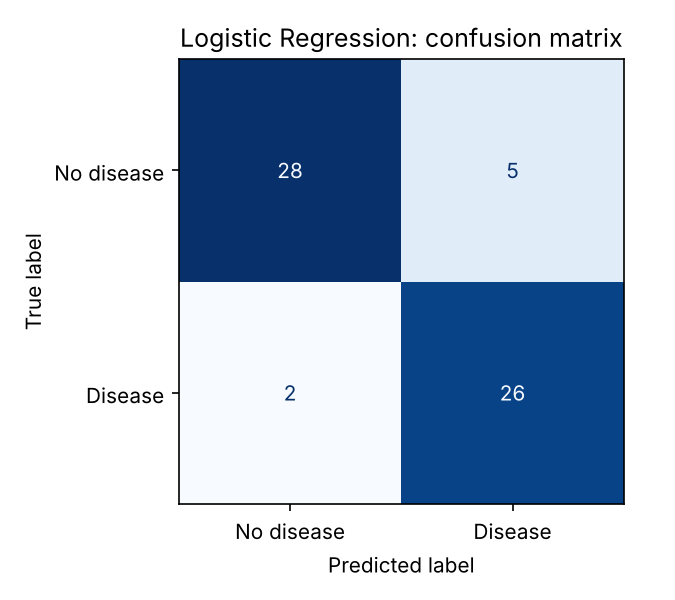

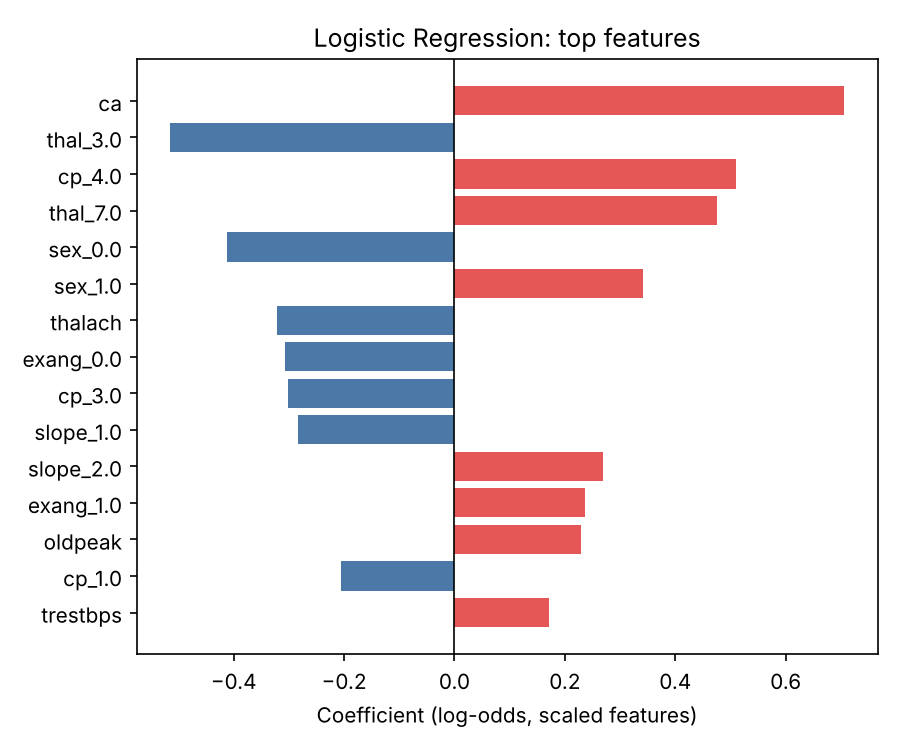

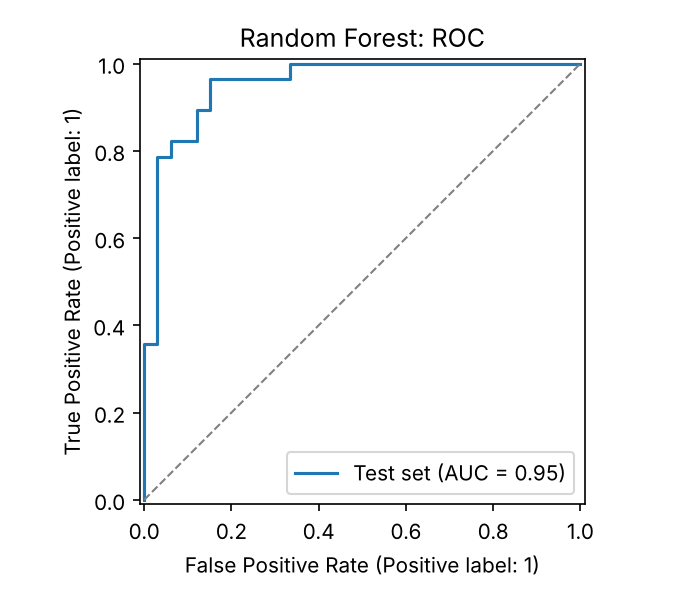

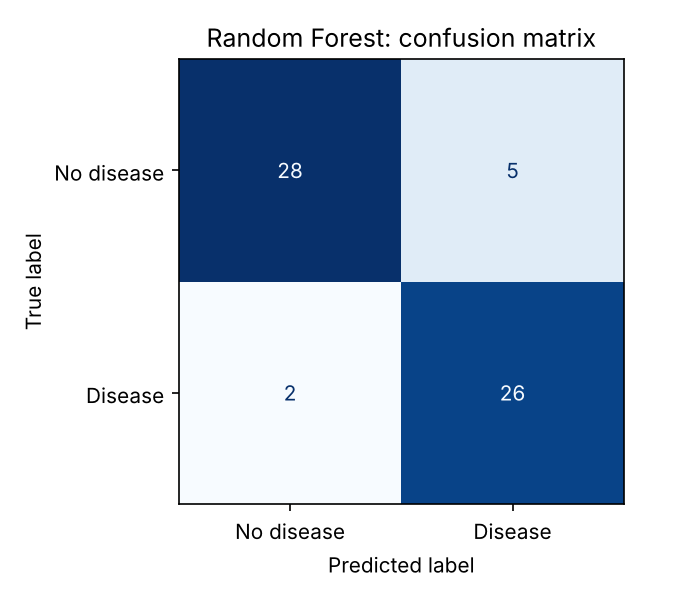

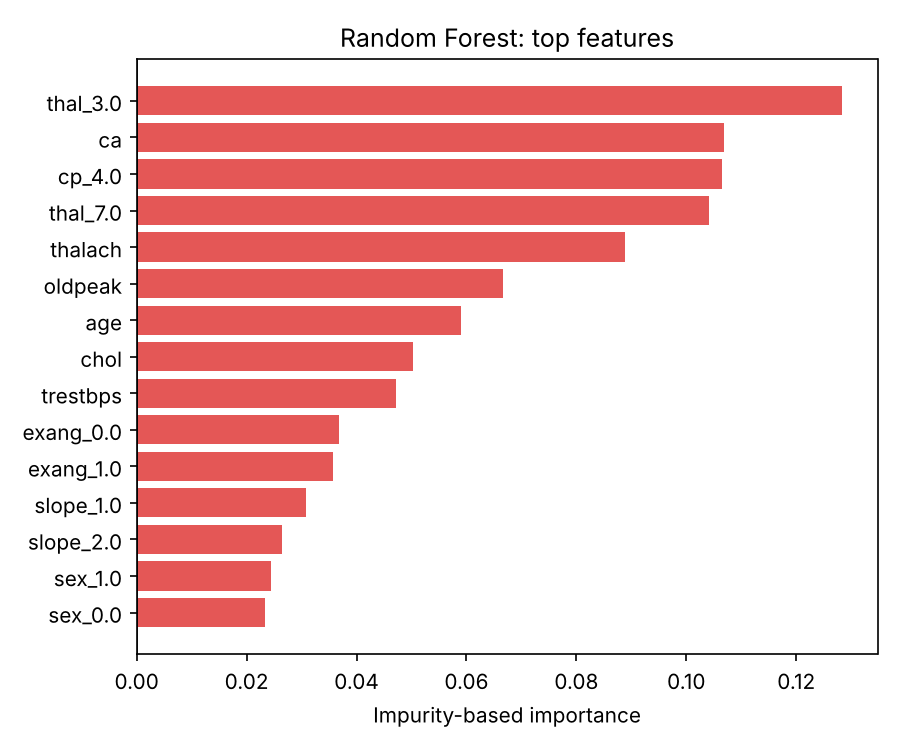

In [6]:
from IPython.display import Image, display
fig = ROOT / "reports/figures/models"
display(Image(filename=str(fig / "model_comparison.png"), width=700))
for m in ["logistic_regression", "random_forest"]:
    for p in ["roc_curve", "confusion_matrix", "feature_importance"]:
        display(Image(filename=str(fig / m / f"{p}.png"), width=420))

## 4. Tuning detail – top Logistic Regression candidates

In [7]:
pd.read_csv(fig / "logistic_regression/cv_results.csv").head(8)

,C,class_weight,l1_ratio,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc
0,0.1,NaN,0.0,0.8469,0.8695,0.7921,0.8262,0.9117
1,0.1,balanced,0.0,0.8427,0.8517,0.8008,0.8229,0.9113
2,1.0,NaN,1.0,0.8428,0.8717,0.7834,0.8216,0.9097
3,1.0,balanced,1.0,0.8386,0.8389,0.8190,0.8245,0.9090
4,0.3,NaN,0.0,0.8429,0.8669,0.7830,0.8196,0.9085
5,0.3,balanced,0.0,0.8387,0.8520,0.7917,0.8167,0.9082
6,3.0,balanced,0.0,0.8429,0.8521,0.8016,0.8246,0.9069
7,1.0,NaN,0.0,0.8470,0.8783,0.7838,0.8254,0.9065


## 5. What MLflow holds

In [8]:
import mlflow
mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
runs = mlflow.search_runs(experiment_names=[config.MLFLOW_EXPERIMENT])
print("total runs:", len(runs))
runs[["tags.mlflow.runName", "metrics.cv_roc_auc_mean", "metrics.test_roc_auc"]].dropna(subset=["metrics.test_roc_auc"])

total runs: 68


,tags.mlflow.runName,metrics.cv_roc_auc_mean,metrics.test_roc_auc
37,random_forest,0.898488,0.953463
66,logistic_regression,0.911694,0.962121
67,baseline_majority_class,0.500000,0.500000


In [9]:
client = mlflow.MlflowClient()
mv = client.get_model_version_by_alias(config.REGISTERED_MODEL_NAME, "champion")
print(f"registered: {mv.name} v{mv.version} (alias champion) from run {mv.run_id}")

registered: heart-disease-classifier v1 (alias champion) from run 8ba78a76c2474065a81e2a9e6c9fc052


Open the UI with `make mlflow-ui` → http://localhost:5000.